> Notebook-friendly copy of `part-II/4.3-clustering-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

# 4.3) (Exercise) Clustering

<img src='https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-II/_static/garbage_cans.jpg?raw=1'>
<center> Photo Credits: <a href='https://unsplash.com/photos/PizD8punZsw'>Three Assorted-Color Garbage Cans</a> by <a href='https://unsplash.com/@julytheseventifirst'>Hamza Javaid</a> licensed under the <a href='https://unsplash.com/license'>Unsplash License</a>
</center>

*Sorting takes a lot of effort - is there a way that we can get computers to do it automatically for us when we don't even know where to begin?*

This notebook will be used in the lab session for week 4 of the course, covers Chapter 9 of the old edition of Géron's book (Chapter 8, "Unsupervised Learning Techniques", in the current *Hands-On Machine Learning with Scikit-Learn and PyTorch* edition), and builds on the [notebooks made available on _Github_](https://github.com/ageron/handson-ml2).

Need a reminder of last week's labs? Click [_here_](https://colab.research.google.com/github/tbeucler/2022_ML_Earth_Env_Sci/blob/main/Lab_Notebooks/Week_3_Decision_Trees_Random_Forests_SVMs.ipynb) to go to notebook for week 3 of the course.

**🎯 Learning objectives**

- Cluster data with k-means, a widely used unsupervised method, using scikit-learn
- Compare k-means trained on the full dataset with k-means trained on the dimensionality-reduced data
- Test the sensitivity of the clusters to the number of clusters k with the silhouette score
- Visualise clusters with t-SNE

**Notebook Setup**

First, let's import a few common modules, ensure MatplotLib plots figures inline and prepare a function to save the figures. We also check that Python 3.5 or later is installed (although Python 2.x may work, it is deprecated so we strongly recommend you use Python 3 instead), as well as Scikit-Learn ≥0.20.

In [36]:
# Common imports
import numpy as np
import os

# to make this notebook's output stable across runs
rnd_seed = 2022
rnd_gen = np.random.default_rng(rnd_seed)

# To plot pretty figures
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Where to save the figures -- shared _files/ dir for this part's generated output
IMAGES_PATH = "_files"
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

**Data Setup**

We need to load the MNIST dataset from OpenML - we won't be loading it as a Pandas dataframe, but will instead use the Dictionary / ndrray representation.

In [37]:
# Chargement de MNIST : 70 000 images de chiffres manuscrits (28x28 = 784 pixels chacune)
from sklearn.datasets import fetch_openml
mnist = fetch_openml('mnist_784', version=1, as_frame=False)

X = mnist['data']                    # les images (70000, 784)
y = mnist['target'].astype(np.uint8) # les vrais chiffres (stockés en texte -> convertis en entiers)
# NB : ici y ne servira PAS à entraîner le clustering (méthode non supervisée),
# seulement à vérifier à la fin si les clusters trouvés ressemblent aux vrais chiffres.

We're going to subsample the digits in the dataset, choosing a random set of digit classes - we won't even know the number of different digits we will chose; it will be somewhere between 4 and 8!

In [38]:
# On tire au hasard quels chiffres on garde (entre 4 et 8 chiffres différents, sans répétition).
# Le but du jeu : on ne sait pas combien de groupes "vrais" il y a, il faudra le deviner avec le clustering.
digits = rnd_gen.choice(np.arange(10), # Chiffres possibles (0 à 9)
                        int( np.round( rnd_gen.uniform(3.5, 8.5) ) ), # Nombre de chiffres différents à utiliser
                        replace = False) # Pas de répétition
# pas moins de 4 pour pas que ça soit trop simple et pas plus de 8 pour pas sous entendre 1 cluster par chiffre

💡 **À retenir** : on tire au hasard entre 4 et 8 chiffres, donc **on ne connaît pas le vrai nombre de groupes**. C'est exactement la situation d'un vrai problème de clustering : le but est de retrouver la structure sans les étiquettes.

We will learn on a total of 8000 digits, evenly distributed amongst the randomly selected digits in the dataset. Let's store the number of samples to be taken from each class.

In [39]:
# Let's find a round number of digits to extract for each digit
num_samples = np.round(8000/len(digits) + 1 ).astype(int)

With that out of the way, let's generate the dataset!

In [40]:
# Placeholder Vars
sub_X = None
sub_y = None

In [41]:
# Boucle sur les chiffres tirés au hasard
for digit in digits:
  # masque booléen : True là où l'image est le chiffre courant
  y_idxs = y==digit

  # rnd_gen.choice tire num_samples images au hasard parmi celles de ce chiffre
  # (par défaut AVEC remise : une même image peut sortir deux fois, ce n'est pas grave ici)
  X_subset = X[y_idxs][rnd_gen.choice(np.arange(y_idxs.sum()),(num_samples,))]
  y_subset = np.full(X_subset.shape[0],digit) # tableau rempli du chiffre courant = les vraies étiquettes

  # On empile les sous-échantillons de chaque chiffre les uns sous les autres
  if type(sub_X) == type(None):
    sub_X = X_subset
    sub_y = y_subset
  else:
    sub_X = np.vstack([sub_X, X_subset])
    sub_y = np.hstack((sub_y,y_subset))

In [42]:
# On mélange le jeu de données (même permutation pour X et y, sinon images et étiquettes ne correspondraient plus)
# et on le coupe à 8000 images pour qu'on ne puisse pas deviner le nombre de chiffres avec la taille du tableau
shuffler = rnd_gen.permutation(len(sub_X))
sub_X = sub_X[shuffler][:8000]
sub_y = sub_y[shuffler][:8000]

We now have a set of 8000 random samples that we know belong to somewhere between 4 and 8 clusters 😃 <br> Can we divide them into these groups without knowing the labels beforehand?

**Warning**: Don't expect near perfect results this time.

Clustering with KMeans

The first thing we need to do is to import the KMeans model from scikit learn. Let's go ahead and do so.

## Q1) Import the KMeans model from scikit learn.

*Hint: [Here is the documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) for the Kmeans implementation in sklearn.*

In [43]:
# Import de la classe KMeans (module sklearn.cluster)
# KMeans : algorithme NON supervisé qui regroupe les images en k groupes (clusters) selon leur ressemblance
from sklearn.cluster import KMeans

We don't know how many clusters we should use to split the data. Our first instinct would be to use as many clusters as the number of digits we have, but even that is not necessarily optimal. Why dont we try all K's between 4 and 40?

To do so, we'll need to begin by training a Kmeans algorithm for each value of K we're interested in.

How long does it take to train a single KMeans model with 10 initial centroid settings? This will give us an idea as to whether it may be a good idea to apply a dimensionality reduction algorithm before fitting our models.

## Q2) Import python's `time` library and measure how long it takes to train a single KMeans model with 3 clusters on the raw data subset.

*Hint 1: [Here is the documetation](https://docs.python.org/3/library/time.html#time.time) for the function used to get timestamps*

In [44]:
# ---------------------------------------------------------------------------------------------------------------
# Import de time pour chronométrer l'entraînement
# ---------------------------------------------------------------------------------------------------------------
import time

In [45]:
# ---------------------------------------------------------------------------------------------------------------
# On chronomètre KMeans comme dans le notebook précédent : on relève l'heure AVANT l'entraînement.
# ---------------------------------------------------------------------------------------------------------------
t0 = time.time()

In [46]:
# --------------------------------------------------------------------------------------------------------------------
# On entraîne KMeans avec 3 clusters et rnd_seed comme random_state, et on relève l'heure APRÈS.
# --------------------------------------------------------------------------------------------------------------------
# KMeans commence avec des centres (centroïdes) placés au hasard, d'où l'intérêt du random_state (reproductibilité).
# Ensuite il répète : (1) chaque image est assignée au centre le plus proche, (2) chaque centre est recalculé
# comme la moyenne de ses images, jusqu'à ce que plus rien ne bouge.
# Attention : pas de y ici ! Le clustering ne voit que les images (fit(X) et non fit(X, y)).
kmeans_test = KMeans(n_clusters=3,n_init=10, # Number of clusters to split into
                     random_state = rnd_seed) # Random seed
kmeans_test.fit(sub_X) # Fitting to data subset
t1 = time.time()

💡 **KMeans en bref** : on choisit un nombre de groupes k. L'algorithme place k centres au hasard, puis répète (1) chaque image est rattachée au centre le plus proche, (2) chaque centre est déplacé à la moyenne de ses images, jusqu'à stabilisation. C'est une méthode **non supervisée** : `fit(sub_X)` ne reçoit jamais `y`. `n_init` (10 par défaut dans les versions récentes de scikit-learn) correspond au nombre de fois où l'algorithme est relancé avec des centres initiaux différents, pour garder le meilleur résultat : c'est pour ça que l'entraînement prend du temps.

In [47]:
print(f"Training took {(t1 - t0):.2f}s")

Training took 1.78s


This should seem like a bit longer than we want. (3.42 seconds during testing of the notebook). Doing this many times means there's a possibility we'll be sitting around doing *nothing*, possiblity for *several minutes*. ***Who has time for this?*** si on fait pour ls 36 modèle ca va être très long alors on cherche à optimiser

Let's reduce the dataset using PCA, capturing 95% of the variability in the data.

## Q3) Import PCA from scikit and reduce the dimensionality of our input data. 95% of the variance in the data should be captured.

*Hint 1: [Here is the documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) for PCA.*

*Hint 2: `.fit_transform()` will be very useful*

In [48]:
#très utile de faire une PCA car un K-means dépend du nombre de variable et une PCA permet de reduire ce nombre. Les distance de centre se caculent 
# entre les pixel donc moins de pixel = plus rapide. 

In [49]:
# --------------------------------------------------------------------------------------------------------------------
# Import de la classe PCA (module sklearn.decomposition)
# --------------------------------------------------------------------------------------------------------------------
from sklearn.decomposition import PCA

# --------------------------------------------------------------------------------------------------------------------
# On crée la PCA en ne gardant que le nombre de composantes nécessaires pour expliquer 95 % de la variance.
# (un nombre FLOTTANT entre 0 et 1 = proportion de variance ; un ENTIER = nombre exact de composantes)
# --------------------------------------------------------------------------------------------------------------------
pca = PCA(n_components=0.95)

In [50]:
# --------------------------------------------------------------------------------------------------------------------
# fit_transform : la PCA apprend les axes principaux sur sub_X puis projette les images dessus (784 variables -> ~150)
# Ici on n'a pas de jeu de test séparé (on fait du clustering, pas de la prédiction), donc on peut tout transformer d'un coup.
# --------------------------------------------------------------------------------------------------------------------
reduced_X = pca.fit_transform(sub_X)
print(f"Dimensions avant : {sub_X.shape[1]}  ->  après : {reduced_X.shape[1]}")

Dimensions avant : 784  ->  après : 133


💡 **Pourquoi la PCA avant KMeans ?** KMeans calcule des distances entre chaque image et chaque centre, donc son temps de calcul augmente avec le nombre de variables. Réduire 784 pixels à ~150 composantes allège ces calculs, pour 95 % de la variance conservée. (Contrairement au Random Forest de l'exercice précédent, KMeans est un algorithme dont le coût dépend surtout du nombre de variables : il profite donc nettement de la réduction.)

Let's try training a KMeans model on the reduced dataset and see if our training time improved...

## Q5) Repeat Q2 using the reduced dataset
*Reminder: We're still splitting the data into 3 clusters*

In [51]:
# --------------------------------------------------------------------------------------------------------------------
# On refait exactement la même chose qu'avant (3 clusters, random_state=rnd_seed) mais sur les données RÉDUITES.
# Le KMeans doit maintenant s'ajuster à reduced_X
# --------------------------------------------------------------------------------------------------------------------
t0 = time.time()
kmeans_test = KMeans(n_clusters=3,n_init=10, # Number of clusters to split into
                     random_state = rnd_seed) # Random seed
kmeans_test.fit(reduced_X) # Fitting to reduced data subset
t1 = time.time()

print(f"Training took {(t1 - t0):.2f}s")

Training took 0.24s


In [52]:
# on a un temps super petit pour un cluster a 3 0.06 s c'est parfait 

## Q6) Train a KMeans model for $\; 2 \le k \le 20$

*Hint 1: Set up a range using python's [`range`](https://docs.python.org/3/library/functions.html#func-range) function or numpy's [`arange`](https://numpy.org/doc/stable/reference/generated/numpy.arange.html)*

*Hint 2: You can store each trained model by appending it to a list as you iterate*

In [53]:
# --------------------------------------------------------------------------------------------------------------------
# Liste des k à tester : de 2 à 20 INCLUS. range(2, 21) s'arrête à 20 (la borne de fin est exclue en Python).
# --------------------------------------------------------------------------------------------------------------------
k_list = range(2, 21)

# --------------------------------------------------------------------------------------------------------------------
# Liste vide pour ranger les modèles entraînés (un par valeur de k)
# --------------------------------------------------------------------------------------------------------------------
kmeans_models = []

In [54]:
# -----------------------------------------------------------------------------------------------------------------------------------
# Boucle for : on entraîne un KMeans pour chaque k et on le stocke. Même code que Q2-Q5, mais k change à chaque tour.
# ------------------------------------------------------------------------------------------------------------------------------------
t0 = time.time() # Get a timestamp to keep track of time
for k in k_list:
    #print out a statement stating which k value you are working on
    t1 = time.time() # Get a current timestamp
    print(f"\r Currently working on k={k}, elapsed time: {(t1 - t0):.2f}s", end="")

    kmeans = KMeans(n_clusters=k,n_init=10, # Set the number of clusters
                    random_state= rnd_seed ) # Set the random state
    kmeans.fit(reduced_X) # Fit the model to the reduced data subset

    kmeans_models.append(kmeans) # store the model trained to predict  k clusters

 Currently working on k=20, elapsed time: 14.64s

In [55]:
# -----------------------------------------------------------------------------------------------------------------------------------
# We spent around 56.5s to train the models
# ------------------------------------------------------------------------------------------------------------------------------------
print(f"\r Finished training the models! It took: {(time.time() - t0):.2f}s")

 Finished training the models! It took: 15.92s


You should hopefully remember the silhouette score and inertia metrics from the reading. Let's go ahead and make a $k$ vs $silhouette$ plot and a $k$ vs $inertia$ plot.

## Q7) Import the silhouette score metric and generate a silhouette score value for each model we trained

*Hint 1: [Here is the documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html) for the Silhouette score implementation in scikit learn*

*Hint 2: The silhouette score needs the model input data and the model labels as arguments*

*Hint 3: The model labels are stored as an attribute in each model. Check the list of available attributes in the [sklearn KMeans documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).*

In [56]:
# --------------------------------------------------------------------------------------------------------------------
# Import de silhouette_score (module sklearn.metrics)
# Le score de silhouette va de -1 à 1 : plus il est proche de 1, plus les clusters sont compacts ET bien séparés
# des autres (0 = clusters qui se chevauchent, négatif = images probablement dans le mauvais cluster).
# --------------------------------------------------------------------------------------------------------------------
from sklearn.metrics import silhouette_score

In [57]:
# --------------------------------------------------------------------------------------------------------------------
# List comprehension : pour chaque modèle entraîné, on calcule le score de silhouette.
# Arguments : (les données utilisées pour entraîner, les clusters attribués à chaque image = model.labels_)
# On utilise reduced_X car c'est sur ces données que les modèles ont été entraînés.
# --------------------------------------------------------------------------------------------------------------------
silhouette_scores = [silhouette_score(reduced_X, model.labels_)
                     for model in kmeans_models]

💡 **Silhouette vs inertie** :
- **Inertie** : somme des distances au carré entre chaque image et son centre. Elle **diminue toujours** quand k augmente (avec k = nombre d'images, elle vaudrait 0), donc on ne peut pas choisir k en prenant la plus petite inertie. On cherche plutôt un « coude » dans la courbe.
- **Silhouette** : compare, pour chaque image, la distance à son propre cluster et celle au cluster voisin le plus proche. Elle peut baisser quand k augmente, donc elle permet de choisir un k.

## Q8) Plot comparing $k$ vs Silhouette Score. Highlight the maximum score

*Hint 1: You'll need to find the position of the best score in the silhouette score list. [Here is the documentation ](https://numpy.org/doc/stable/reference/generated/numpy.argmax.html)to a numpy function that would be very useful for this.*

*Hint 2: matplotlib's pyplot has been imported as `plt`. [Here is the documentation](https://matplotlib.org/3.5.0/api/_as_gen/matplotlib.pyplot.subplots.html) to the `subplots()` method.*

*Hint 3: [Here is the documentation](https://matplotlib.org/3.5.0/api/_as_gen/matplotlib.pyplot.plot.html) to the `plot()` method in matplotlib's pyplot. Note that it is also implemented as a method in the `axes` objects created with `plt.subplots()`*

In [58]:
# --------------------------------------------------------------------------------------------------------------------------------------------------
# np.argmax renvoie la POSITION (l'indice) du plus grand élément. On convertit d'abord la liste en tableau NumPy.
# --------------------------------------------------------------------------------------------------------------------------------------------------
best_index = np.argmax(np.array(silhouette_scores))

In [59]:
# --------------------------------------------------------------------------------------------------------------------------------------------------
# best_index est une POSITION dans la liste (0 = premier modèle = k=2), pas la valeur de k : on la convertit avec k_list.
# --------------------------------------------------------------------------------------------------------------------------------------------------
best_k = k_list[best_index] # Get the best K value, per the silhouette score

# --------------------------------------------------------------------------------------------------------------------------------------------------
# Score de silhouette du meilleur modèle
# --------------------------------------------------------------------------------------------------------------------------------------------------
best_score = silhouette_scores[best_index]
print(f"Meilleur k selon la silhouette : {best_k} (score = {best_score:.3f})")

Meilleur k selon la silhouette : 2 (score = 0.162)


In [60]:
print(len(kmeans_models), len(silhouette_scores), len(k_list))   # doit afficher 19 19 19

19 19 19


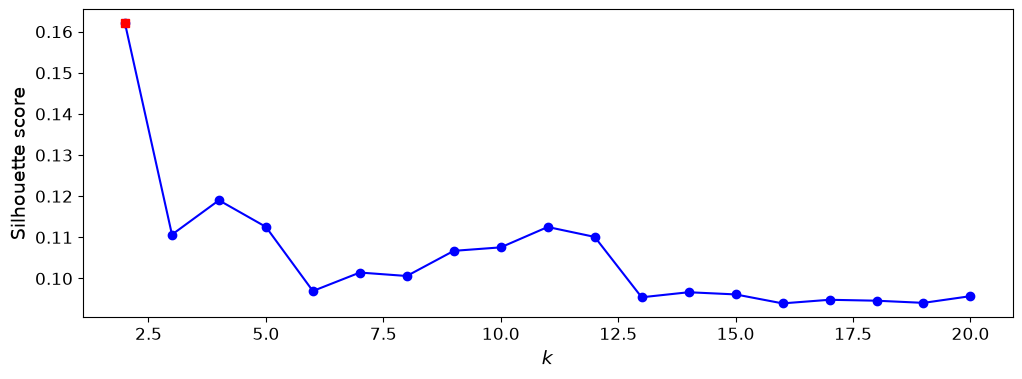

In [61]:
# --------------------------------------------------------------------------------------------------------------------------------------------------
# Graphique k vs score de silhouette (axe horizontal : k, axe vertical : silhouette)
# --------------------------------------------------------------------------------------------------------------------------------------------------
# Make a figure with size (12,4)
fig, ax = plt.subplots(figsize=(12,4))

ax.plot(k_list, silhouette_scores, "bo-")
ax.set_xlabel("$k$", fontsize=14)
ax.set_ylabel("Silhouette score", fontsize=14)

ax.plot(best_k, best_score, "rs") # carré rouge = meilleur score
plt.show()

💡 Le carré rouge marque le k au score de silhouette maximal. Les valeurs exactes dépendent de la graine aléatoire (`rnd_seed = 2022`) et du tirage des chiffres : compare l'allure générale avec la figure ci-dessous.

We got this figure when we ran the code. Does your figure look the same?

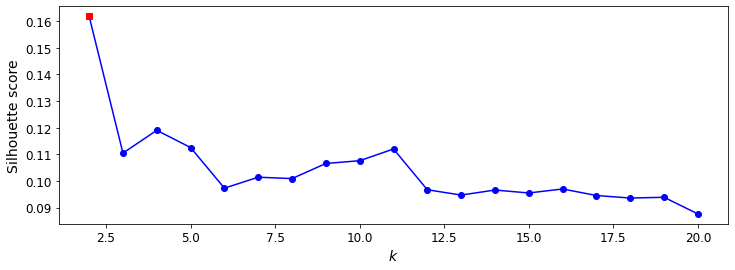

Now we'll plot the value of $k$ vs inertia

## Q9) Plot comparing $k$ vs Inertia. Highlight the inertia for the model with the highest silhouette score

*Hint 1: If you followed the previous step as it was written, you have the index for the best model stored in*`best_index`.

*Hint 2: [The KMeans documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html#sklearn.cluster.KMeans) details the attribute in which the model's intertia is stored.*

In [62]:
# --------------------------------------------------------------------------------------------------------------------------------------------------
# L'inertie = somme des distances au carré entre chaque image et le centre de son cluster.
# Plus elle est basse, plus les clusters sont "serrés". Elle est stockée dans l'attribut inertia_ de chaque modèle.
# --------------------------------------------------------------------------------------------------------------------------------------------------
inertias = [model.inertia_ for model in kmeans_models]

# --------------------------------------------------------------------------------------------------------------------------------------------------
# Inertie du modèle qui a le meilleur score de silhouette (même position best_index)
# --------------------------------------------------------------------------------------------------------------------------------------------------
best_inertia = inertias[best_index]

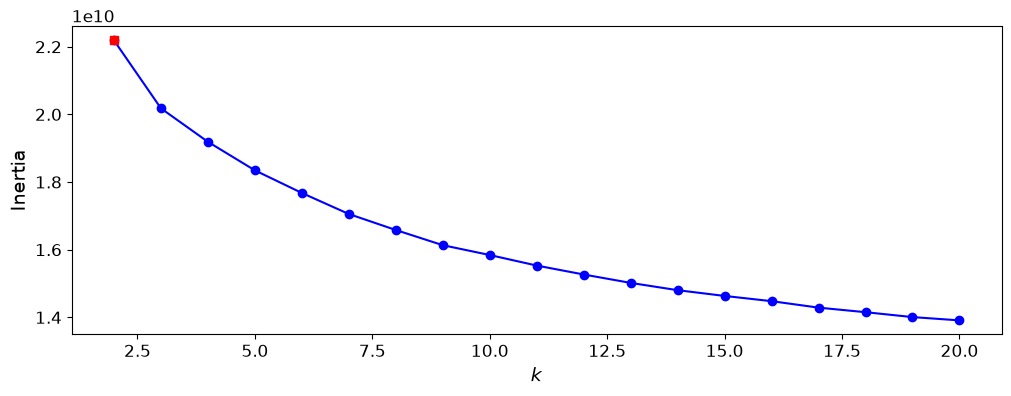

In [63]:
# --------------------------------------------------------------------------------------------------------------------------------------------------
# Graphique k vs inertie (axe horizontal : k, axe vertical : inertie)
# --------------------------------------------------------------------------------------------------------------------------------------------------
# Make a figure with size (12,4)
fig, ax = plt.subplots(figsize=(12,4))

ax.plot(k_list, inertias, "bo-")

ax.set_xlabel("$k$", fontsize=14)
ax.set_ylabel("Inertia", fontsize=14)

ax.plot(best_k, best_inertia, "rs") # carré rouge = k choisi par la silhouette
plt.show()

You should see a figure similar to the one below.

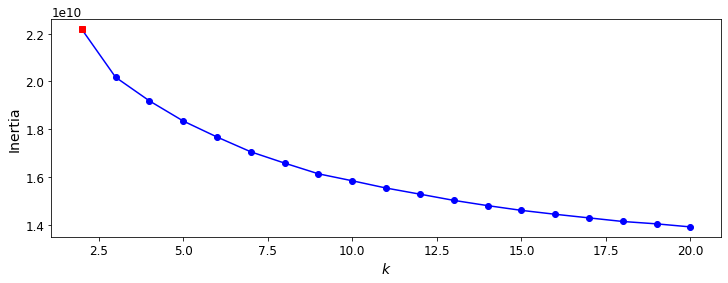

If you ran the notebook with the default random seed, you may be surprised to see that the best performing KMeans model is the one that breaks it off into two clusters! The next best two will be those associated with $k=4$ and $k=5$. Let's get some plots to try to make sense of the results, since we have the actual labels.

There aren't any more questions to answer from here on out, but you *will* have to change the code if you started out from a different random seed! I'll try to be good about pointing out what code you'll need to change.

Let's begin by using [scikit's TSNE implementation](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) to reduce the dimensionality of the dataset for plotting. This will take a bit of computation time!

In [64]:
from sklearn.manifold import TSNE

# t-SNE : méthode de réduction de dimension faite pour VISUALISER (pas pour entraîner un modèle).
# Elle projette les images en 2D en essayant de garder proches les images qui se ressemblent.
# On l'utilise uniquement pour dessiner les clusters. Les axes X1/X2 n'ont pas de signification propre.
tsne = TSNE(n_components=2, # We'll project onto 2D plane
            random_state=rnd_seed, # We need a random seed
            learning_rate='auto') #Let the algorithm handle the learning rate

# And now get the input data in 2-component reduced form
X_plot = tsne.fit_transform(sub_X)

💡 **t-SNE** sert uniquement à **dessiner** les données en 2D. Les clusters ont été calculés sur `reduced_X` (PCA), pas sur ces coordonnées 2D. On colorie ensuite le même nuage de points avec les vrais chiffres, puis avec les clusters prédits, pour comparer.

Let's continue by making a list of the three best models.

In [65]:
# --------------------------------------------------------------------------------------------------------------------------------------------------
# Liste vide pour ranger les trois meilleurs modèles
# --------------------------------------------------------------------------------------------------------------------------------------------------
best_models = []

In [66]:
# --------------------------------------------------------------------------------------------------------------------------------------------------
# On récupère le meilleur modèle avec best_index
# --------------------------------------------------------------------------------------------------------------------------------------------------
best_models.append(kmeans_models[best_index])

In [67]:
# --------------------------------------------------------------------------------------------------------------------------------------------------
# On récupère manuellement le 2e et le 3e meilleur modèle.
# np.argsort() renvoie les positions triées du plus petit au plus grand score : le dernier indice (-1) est le meilleur,
# l'avant-dernier (-2) est le 2e meilleur et l'antépénultième (-3) le 3e meilleur.
# --------------------------------------------------------------------------------------------------------------------------------------------------
second_index,third_index = np.argsort(np.asarray(silhouette_scores))[-2], np.argsort(np.asarray(silhouette_scores))[-3]
best_models.append(kmeans_models[second_index])
best_models.append(kmeans_models[third_index])

And now, let's get a set of predictions for each model and store it in a list!

In [68]:
# model.predict(...) assigne chaque image à un cluster. On doit lui donner des données dans le MÊME espace
# que celles de l'entraînement, donc reduced_X (les modèles ont été entraînés sur les données réduites par la PCA).
pred_labels = []
for model in best_models:
    pred_labels.append(model.predict(reduced_X))

💡 Les numéros de clusters (0, 1, 2…) sont **arbitraires** : le cluster « 0 » ne correspond pas forcément au chiffre 0. Un modèle non supervisé ne connaît pas les chiffres, il numérote juste ses groupes.

Pandas will make producing a nice plot a lot simpler. Let's import it and make a dataframe with the reduced input components, the truth labels, and the predicted cluster labels.

Note that the predicted labels don't correspond to the digit labels since this is an unsupervised model!

In [69]:
import pandas as pd

plot_data = np.stack([X_plot[:,0], X_plot[:,1], sub_y, *pred_labels],axis=1)
df = pd.DataFrame(plot_data, columns=['X1','X2','truth','pred_1','pred_2','pred_3'])

And now we'll make a nice, big 4x4 plot that allows us to see the true answers and how our algorithm clustered our data!

(np.float64(-108.67426910400391),
 np.float64(99.63517608642579),
 np.float64(-83.33841209411621),
 np.float64(90.01453666687011))

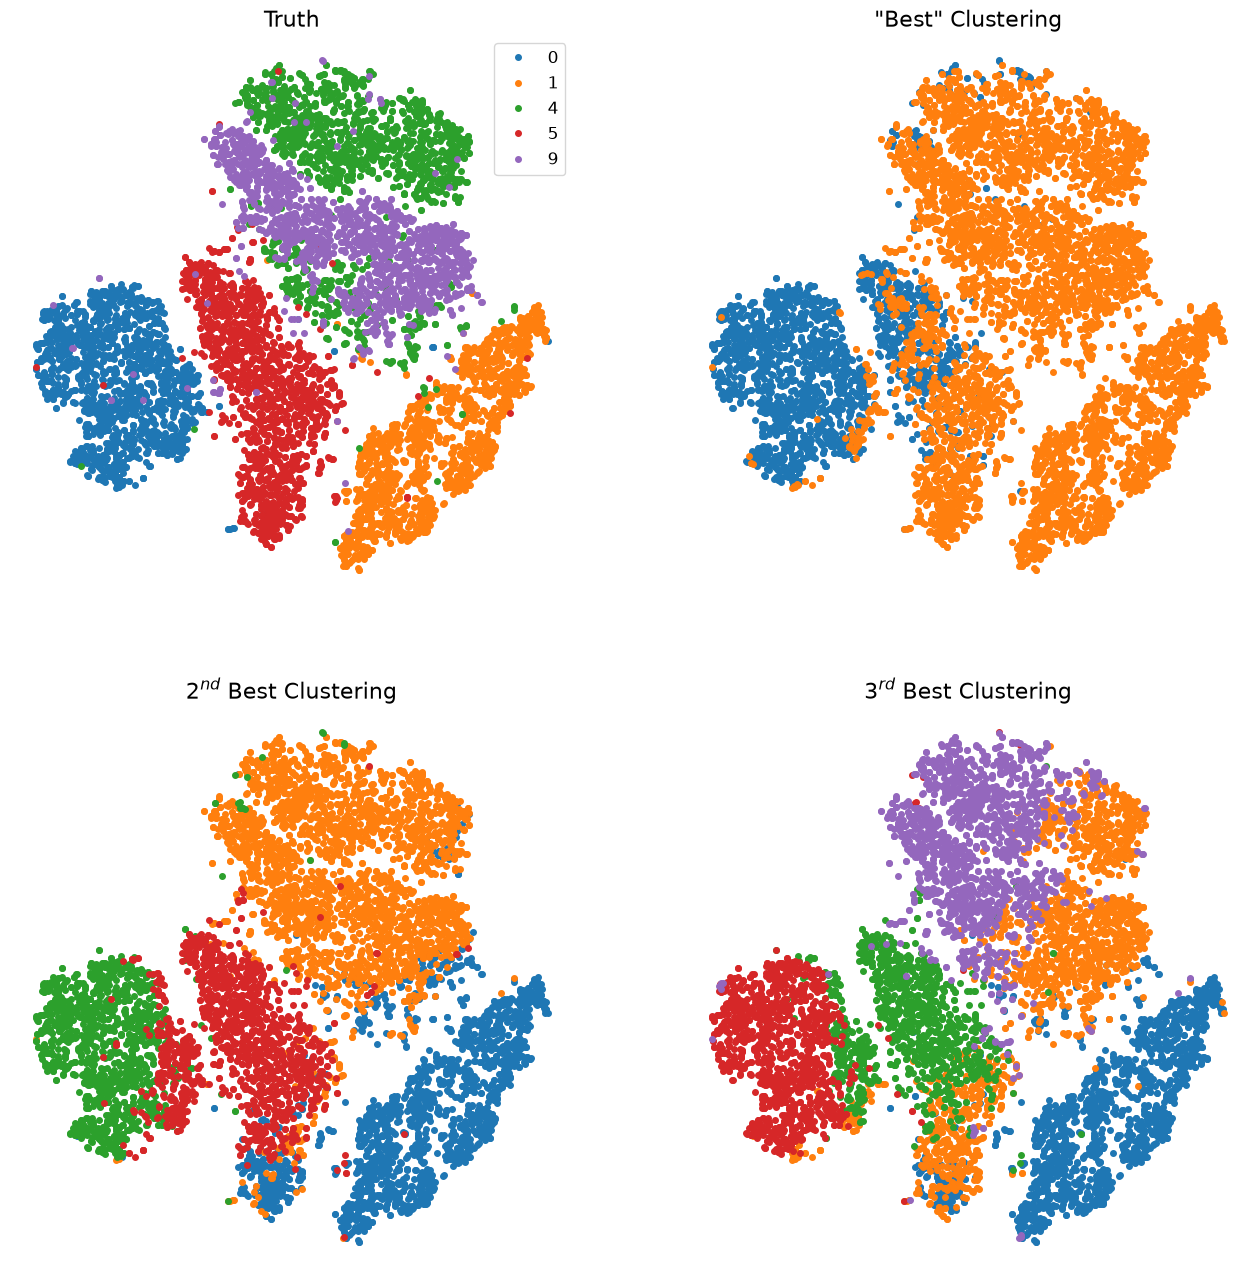

In [70]:
fig, axes = plt.subplots(2, 2, figsize=(16,16))

groups = df.groupby('truth')
for label, group in groups:
    axes[0,0].plot(group.X1, group.X2, marker='o', linestyle='', markersize=4, label=int(label))
axes[0,0].legend(fontsize=12)
axes[0,0].set_title('Truth', fontsize=16)
axes[0,0].axis('off')

groups = df.groupby('pred_1')
for label, group in groups:
    axes[0,1].plot(group.X1, group.X2, marker='o', linestyle='', markersize=4)
axes[0,1].set_title('"Best" Clustering', fontsize=16)
axes[0,1].axis('off')

groups = df.groupby('pred_2')
for label, group in groups:
    axes[1,0].plot(group.X1, group.X2, marker='o', linestyle='', markersize=4)
axes[1,0].set_title('$2^{nd}$ Best Clustering', fontsize=16)
axes[1,0].axis('off')

groups = df.groupby('pred_3')
for label, group in groups:
    axes[1,1].plot(group.X1, group.X2, marker='o', linestyle='', markersize=4)
axes[1,1].set_title('$3^{rd}$ Best Clustering', fontsize=16)
axes[1,1].axis('off')

Our figure looks like this.

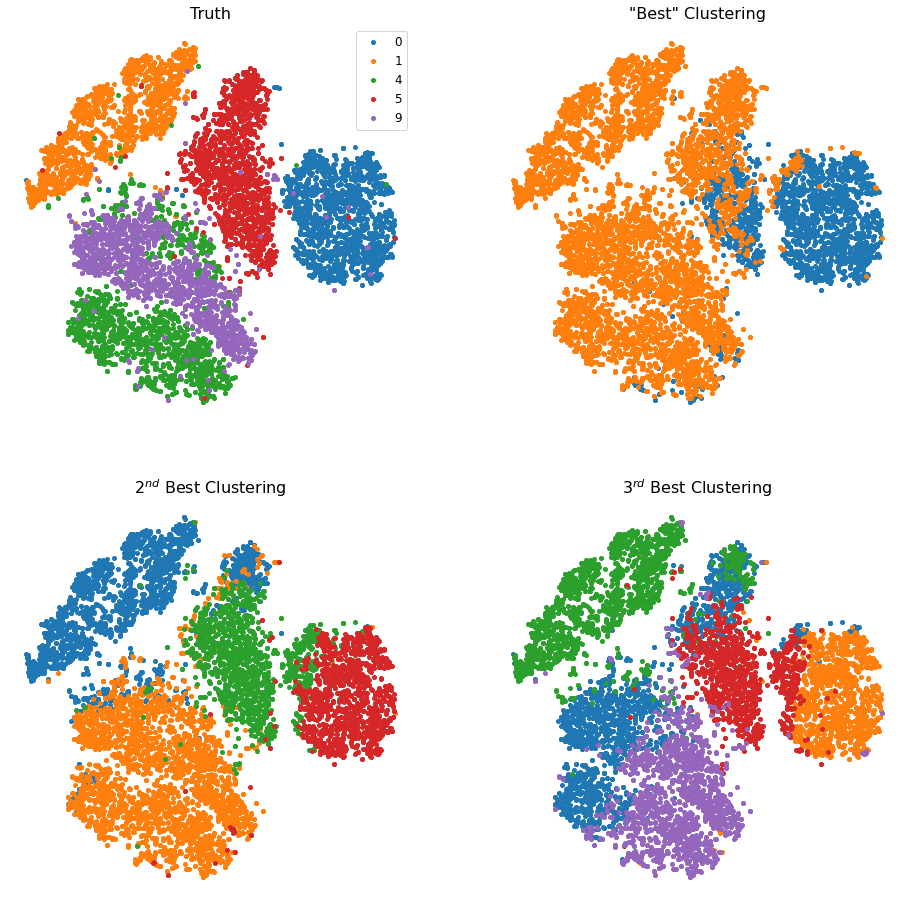

Assuming you started out from the intended random seed, you'll be able to see that the "Best" model is trying to separate the 0 digits from the non-zero digits. The $2^{nd}$ best model is able to separate the digits pretty well, but lumps 4s and 9s into a single cluster!

The $3^{rd}$ best model begins to group digits into clusters that may not have much significance to us at first glance, but whose metrics seem to indicate worse performance and whose results would need further analysis to try to understand.

## Synthèse : ce qu'on observe

**Choix de k.** Le score de silhouette est maximal pour un k petit (souvent k = 2 avec la graine par défaut), alors que le nombre réel de chiffres tirés est entre 4 et 8. Les chiffres manuscrits se ressemblent et se chevauchent (4 et 9, 3 et 5, 7 et 1), donc les clusters ne sont pas bien séparés. La silhouette favorise alors une coupure grossière et nette (par exemple les 0, très différents des autres, contre tout le reste).

**Silhouette et vérité.** Le « meilleur » score de silhouette n'est donc pas forcément le meilleur découpage pour nous. Ici on connaît les vrais chiffres, ce qui permet de voir que le 2e meilleur modèle (k plus proche du vrai nombre de chiffres) est plus parlant. Dans un vrai problème, on n'a pas les étiquettes : il faut combiner silhouette, courbe d'inertie (coude) et connaissance du domaine.

**Inertie.** Elle décroît sans cesse quand k augmente (aucun minimum utile), donc elle ne se lit que par son « coude ».

**Effet de la PCA.** Réduire à 95 % de la variance accélère l'entraînement de KMeans, car moins de variables rendent chaque calcul de distance moins coûteux. On perd un peu d'information, mais l'objectif (trouver des groupes) est conservé.

**Non supervisé.** Le clustering n'utilise jamais `y`. Les vrais chiffres ne servent qu'à vérifier visuellement les résultats avec t-SNE. Les numéros de clusters sont arbitraires.

**Limite.** KMeans suppose des clusters à peu près sphériques et de taille comparable. Les chiffres, qui forment des nuages irréguliers, ne respectent pas bien cette hypothèse, d'où la remarque de l'énoncé : « ne vous attendez pas à des résultats quasi parfaits ».